# Nintendo Switch 2 - Bass Model Analysis

This notebook estimates Bass model parameters from the original Nintendo Switch and uses them to forecast Nintendo Switch 2 adoption.

## 1. Load the data and define the Bass model

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

ROOT = Path('.')
hist = pd.read_csv(ROOT / 'data' / 'dataset1.csv')
hist[['fiscal_year_end','hardware_sales_m','cumulative_sales_m']]

,fiscal_year_end,hardware_sales_m,cumulative_sales_m
0,2017,2.74,2.74
1,2018,15.05,17.79
2,2019,16.95,34.74
3,2020,21.03,55.77
4,2021,28.83,84.60
5,2022,23.06,107.66
6,2023,17.97,125.63
7,2024,15.70,141.33
8,2025,10.80,152.13


In [2]:
def bass_cumulative(t, p, q, M):
    t = np.asarray(t, dtype=float)
    e = np.exp(-(p + q) * t)
    return M * (1 - e) / (1 + (q / p) * e)

## 2. Estimate $p$, $q$, and $M$ from the original Switch

In [3]:
t = hist['elapsed_years'].to_numpy()
y = hist['cumulative_sales_m'].to_numpy()

params, _ = curve_fit(
    bass_cumulative, t, y,
    p0=[0.03, 0.40, 165],
    bounds=([1e-6, 1e-6, 120], [1, 3, 300]),
    maxfev=100000
)
p, q, M = params
print(f'p = {p:.4f}')
print(f'q = {q:.4f}')
print(f'M = {M:.2f} million units')

p = 0.0701
q = 0.4351
M = 170.81 million units


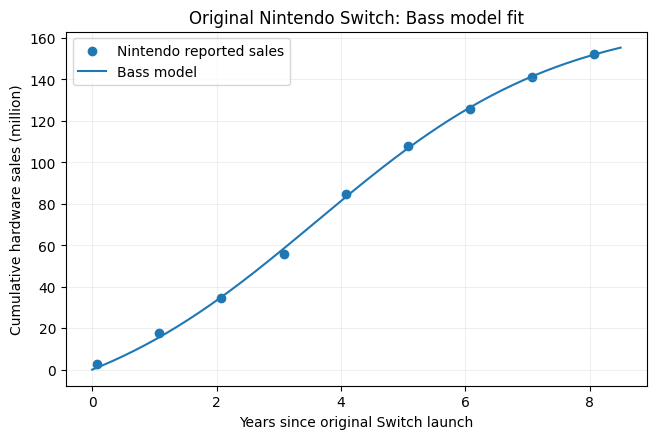

In [4]:
grid = np.linspace(0, 8.5, 300)
plt.figure(figsize=(7.5,4.6))
plt.scatter(t, y, label='Nintendo reported sales')
plt.plot(grid, bass_cumulative(grid,p,q,M), label='Bass model')
plt.xlabel('Years since original Switch launch')
plt.ylabel('Cumulative hardware sales (million)')
plt.title('Original Nintendo Switch: Bass model fit')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

The estimated imitation coefficient is much larger than the innovation coefficient. For a game console, this is reasonable because adoption can increase as the platform becomes more popular, more games are released, and more people in a user's social circle own it.

## 3. Forecast Nintendo Switch 2

Nintendo reported 19.86 million cumulative Switch 2 units by March 31, 2026. I use that actual value as the starting point, then apply the Bass adoption equation each year using the parameters estimated above.

In [5]:
N = 19.86
rows = [[
    2026, N, N, 'Actual',
    'https://www.nintendo.co.jp/ir/pdf/2026/260508e.pdf'
]]
for fy in range(2027, 2036):
    new_adopters = (p + q * N / M) * (M - N)
    N += new_adopters
    rows.append([
        fy, new_adopters, N, 'Forecast',
        'Bass model using p, q, and M estimated from dataset1.csv'
    ])

forecast = pd.DataFrame(
    rows,
    columns=['fiscal_year_end','new_adopters_m','cumulative_adopters_m','type','source_or_basis']
)
forecast

,fiscal_year_end,new_adopters_m,cumulative_adopters_m,type,source_or_basis
0,2026,19.860000,19.860000,Actual,https://www.nintendo.co.jp/ir/pdf/2026/260508e...
1,2027,18.222303,38.082303,Forecast,"Bass model using p, q, and M estimated from da..."
2,2028,22.183128,60.265432,Forecast,"Bass model using p, q, and M estimated from da..."
3,2029,24.721766,84.987198,Forecast,"Bass model using p, q, and M estimated from da..."
4,2030,24.597247,109.584445,Forecast,"Bass model using p, q, and M estimated from da..."
5,2031,21.383296,130.967741,Forecast,"Bass model using p, q, and M estimated from da..."
6,2032,16.084828,147.052569,Forecast,"Bass model using p, q, and M estimated from da..."
7,2033,10.564117,157.616686,Forecast,"Bass model using p, q, and M estimated from da..."
8,2034,6.221151,163.837837,Forecast,"Bass model using p, q, and M estimated from da..."
9,2035,3.397613,167.235450,Forecast,"Bass model using p, q, and M estimated from da..."


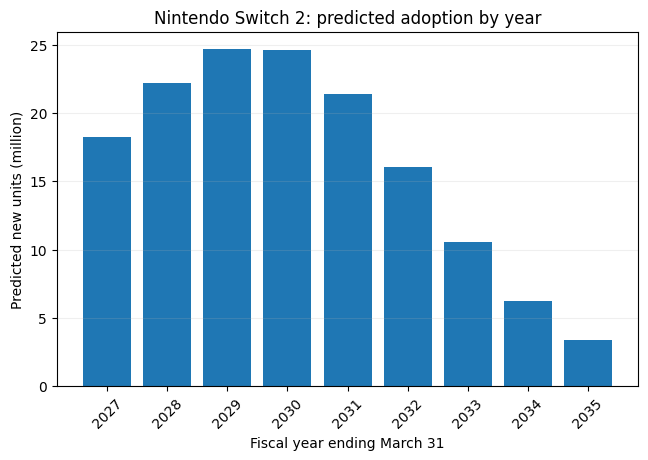

In [6]:
future = forecast[forecast['type']=='Forecast']
plt.figure(figsize=(7.5,4.6))
plt.bar(future['fiscal_year_end'].astype(str), future['new_adopters_m'])
plt.xlabel('Fiscal year ending March 31')
plt.ylabel('Predicted new units (million)')
plt.title('Nintendo Switch 2: predicted adoption by year')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.2)
plt.show()

## 4. Main result

The model gives a long-run market potential of about 171 million units. Starting from the actual fiscal-2026 sales, the forecast reaches about 167 million cumulative units by fiscal 2035. The numbers should be treated as a baseline because console sales also depend on price, competition, game releases, supply, and upgrade behavior.